In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "geraldmc/plantvillage-full",
    split="train"
)

print("Total images:", len(dataset))
print("Available crop-disease classes:")
print(dataset.features["class_label"].names
      if hasattr(dataset.features["class_label"], "names")
      else sorted(set(dataset["class_label"])))

README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Total images: 54304
Available crop-disease classes:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider

Step 1: Check the dataset format

In [ ]:
print("Dataset columns:", dataset.column_names)
print("First image example:")
print(dataset[0])

Dataset columns: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']
First image example:
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x79966C779400>, 'class_label': 'Apple___Apple_scab', 'class_idx': 0, 'host': 'Apple', 'disease': 'Apple scab', 'split': 'test', 'leaf_id': 'Apple___Apple_scab::leaf_79', 'leaf_grouped': True}


Step 2: Display some leaf images

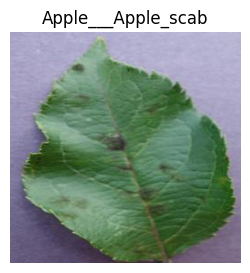

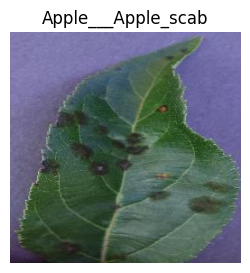

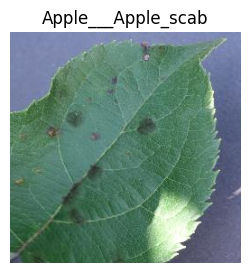

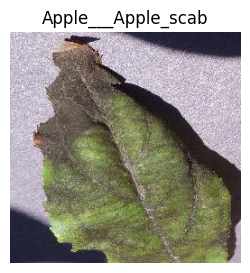

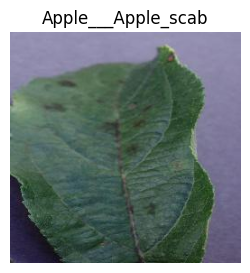

In [ ]:
import matplotlib.pyplot as plt

for i in range(5):
    image = dataset[i]["image"]
    label = dataset[i]["class_label"]

    plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.title(str(label))
    plt.axis("off")
    plt.show()

 step 3: Step 4: Split the dataset into training and validation sets

In [ ]:

from sklearn.model_selection import train_test_split

# Get the class label for every image
labels = dataset["class_label"]

# Split images while preserving class proportions
train_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Create the training and validation datasets
train_data = dataset.select(train_idx)
val_data = dataset.select(val_idx)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Training classes:", len(set(train_data["class_label"])))
print("Validation classes:", len(set(val_data["class_label"])))


Training images: 43443
Validation images: 10861
Training classes: 38
Validation classes: 38


Step 5: Check that the split worked

In [ ]:

print("Total images:", len(dataset))
print("Training images:", len(train_data))
print("Validation images:", len(val_data))

print("Training classes:", len(set(train_data["class_label"])))
print("Validation classes:", len(set(val_data["class_label"])))

assert len(train_data) + len(val_data) == len(dataset)
assert len(set(train_data["class_label"])) == 38
assert len(set(val_data["class_label"])) == 38

print("Dataset split verified successfully!")


Total images: 54304
Training images: 43443
Validation images: 10861
Training classes: 38
Validation classes: 38
Dataset split verified successfully!


In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "geraldmc/plantvillage-full",
    split="train"
)

print("Total images:", len(dataset))
print("Dataset loaded successfully!")

README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Total images: 54304
Dataset loaded successfully!


Step 6 — Create a memory-efficient data pipeline

In [ ]:

import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 38

# Use the existing class order
class_names = sorted(set(dataset["class_label"]))
label_to_id = {name: i for i, name in enumerate(class_names)}

def preprocess(example):
    image = tf.convert_to_tensor(
        np.array(example["image"].convert("RGB")),
        dtype=tf.uint8
    )
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    label = label_to_id[example["class_label"]]
    return image, label

def make_generator(data):
    for example in data:
        image, label = preprocess(example)
        yield image, label

output_signature = (
    tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.int32)
)

train_ds = tf.data.Dataset.from_generator(
    lambda: make_generator(train_data),
    output_signature=output_signature
).shuffle(1000).batch(BATCH_SIZE).prefetch(1)

val_ds = tf.data.Dataset.from_generator(
    lambda: make_generator(val_data),
    output_signature=output_signature
).batch(BATCH_SIZE).prefetch(1)

print("Training batches:", len(train_data) // BATCH_SIZE)
print("Validation batches:", len(val_data) // BATCH_SIZE)
print("Classes:", len(class_names))
print("Data pipeline created successfully!")


Training batches: 1357
Validation batches: 339
Classes: 38
Data pipeline created successfully!


Step 7: Build the MobileNetV2 model

In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load the pretrained MobileNetV2 model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Add our 38-class disease classifier
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(38, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 8A: Fix the data pipeline

In [ ]:

import math

# Recreate the training pipeline with repeat()
train_ds = tf.data.Dataset.from_generator(
    lambda: make_generator(train_data),
    output_signature=output_signature
).shuffle(1000).batch(BATCH_SIZE).repeat().prefetch(1)

# Recreate the validation pipeline with repeat()
val_ds = tf.data.Dataset.from_generator(
    lambda: make_generator(val_data),
    output_signature=output_signature
).batch(BATCH_SIZE).repeat().prefetch(1)

steps_per_epoch = math.ceil(len(train_data) / BATCH_SIZE)
validation_steps = math.ceil(len(val_data) / BATCH_SIZE)

print("Training steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)
print("Pipeline fixed!")


Training steps per epoch: 1358
Validation steps: 340
Pipeline fixed!


Step 8B: Train the model again

In [ ]:

# Train for only 3 epochs initially
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    steps_per_epoch=200,
    validation_steps=50,
    callbacks=[early_stop]
)


Epoch 1/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 452s 2s/step - accuracy: 0.6570 - loss: 1.3281 - val_accuracy: 0.8600 - val_loss: 0.5680
Epoch 2/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 433s 2s/step - accuracy: 0.8602 - loss: 0.5060 - val_accuracy: 0.8988 - val_loss: 0.3879
Epoch 3/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 435s 2s/step - accuracy: 0.8883 - loss: 0.3859 - val_accuracy: 0.9156 - val_loss: 0.3079


Step 9: Check your training results

In [ ]:

print("Completed epochs:", len(history.history["loss"]))

print(
    "Final training accuracy:",
    round(history.history["accuracy"][-1] * 100, 2), "%"
)

print(
    "Final validation accuracy:",
    round(history.history["val_accuracy"][-1] * 100, 2), "%"
)


Completed epochs: 3
Final training accuracy: 88.83 %
Final validation accuracy: 91.56 %


Step 10: Plot the accuracy

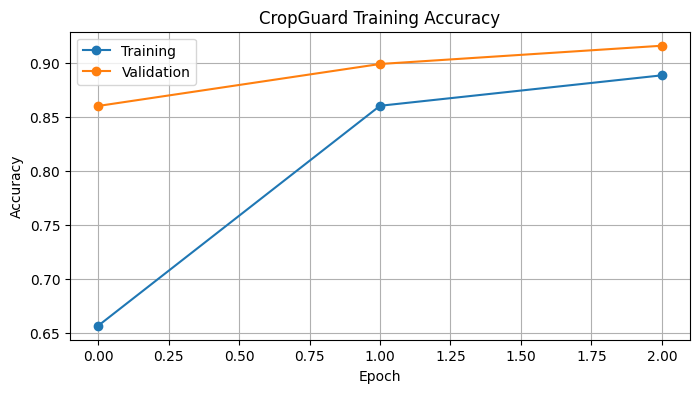

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CropGuard Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

print("Completed epochs:", len(history.history["loss"]))

print("Training accuracy:",
      round(history.history["accuracy"][-1] * 100, 2), "%")

print("Validation accuracy:",
      round(history.history["val_accuracy"][-1] * 100, 2), "%")


Completed epochs: 3
Training accuracy: 88.83 %
Validation accuracy: 91.56 %


Step 10: Save your trained model

In [ ]:

import os
import json

# Create a folder in Google Drive
from google.colab import drive
drive.mount('/content/drive')

save_dir = "/content/drive/MyDrive/CropGuard/model"
os.makedirs(save_dir, exist_ok=True)

# Save the trained model
model.save(os.path.join(save_dir, "crop_disease_model.keras"))

# Save the matching class names
with open(os.path.join(save_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("Model saved successfully!")
print("Location:", save_dir)
print("Number of classes:", len(class_names))


Mounted at /content/drive
Model saved successfully!
Location: /content/drive/MyDrive/CropGuard/model
Number of classes: 38


Step 11: Confirm the files were saved

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/CropGuard/model"))

['crop_disease_model.keras', 'class_names.json']


Step 12: Test the model with a leaf image

Saving Screenshot 2026-10-20 212542.png to Screenshot 2026-10-20 212542.png


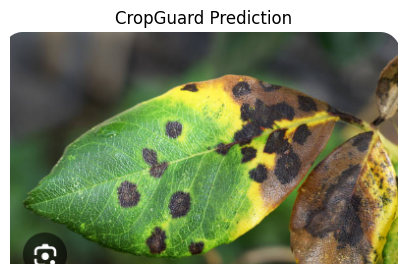

Predicted class: Tomato___Early_blight
Model confidence: 24.62 %


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import json

# Upload a leaf image from your computer
uploaded = files.upload()

image_path = next(iter(uploaded))

# Load the image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare the image for prediction
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict the crop disease
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

# Display the image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("CropGuard Prediction")
plt.show()

print("Predicted class:", predicted_class)
print("Model confidence:", round(confidence, 2), "%")


Step 13: See the top 5 predictions

In [ ]:

top_indices = np.argsort(predictions)[-5:][::-1]

print("Top 5 CropGuard predictions:\n")

for i in top_indices:
    print(
        f"{class_names[i]}: "
        f"{predictions[i] * 100:.2f}%"
    )


Top 5 CropGuard predictions:

Tomato___Early_blight: 24.62%
Peach___Bacterial_spot: 20.70%
Tomato___Late_blight: 10.94%
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 9.80%
Pepper,_bell___Bacterial_spot: 6.12%


Step 14: Improve the model training

In [ ]:

history_more = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1,
    steps_per_epoch=100,
    validation_steps=20
)



100/100 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.9181 - loss: 0.2908 - val_accuracy: 0.9094 - val_loss: 0.3045


Saving Screenshot 2026-10-20 213554.png to Screenshot 2026-10-20 213554.png


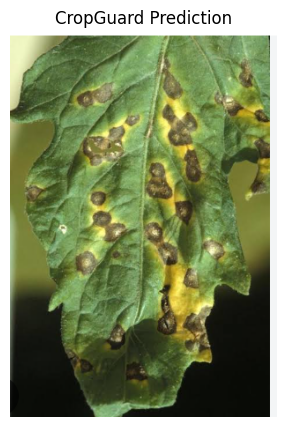

Predicted class: Tomato___Late_blight
Model confidence: 55.24 %


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import json

# Upload a leaf image from your computer
uploaded = files.upload()

image_path = next(iter(uploaded))

# Load the image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare the image for prediction
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict the crop disease
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

# Display the image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("CropGuard Prediction")
plt.show()

print("Predicted class:", predicted_class)
print("Model confidence:", round(confidence, 2), "%")


Step 15: Save the updated model

In [ ]:
import os
import json

save_dir = "/content/drive/MyDrive/CropGuard/model"
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, "crop_disease_model.keras"))

with open(os.path.join(save_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("Updated model saved successfully!")

Updated model saved successfully!


Step 16: Evaluate your model on the validation dataset

In [ ]:

import numpy as np
from sklearn.metrics import classification_report

# Evaluate on 100 validation batches for a faster check
y_true = []
y_pred = []

for images, labels in val_ds.take(100):
    probs = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probs, axis=1))

print("Images evaluated:", len(y_true))
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


Images evaluated: 3200
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.90      0.87      0.88        30
                                 Apple___Black_rot       0.97      0.97      0.97        39
                          Apple___Cedar_apple_rust       0.88      0.94      0.91        16
                                   Apple___healthy       0.93      0.94      0.94        89
                               Blueberry___healthy       0.99      1.00      0.99        85
          Cherry_(including_sour)___Powdery_mildew       0.98      0.95      0.97        65
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00        52
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.62      0.69      0.65        26
                       Corn_(maize)___Common_rust_       0.99      1.00      0.99        70
               Corn_(maize)___Northern_Leaf_Blight      

Step 17: Save your final model

In [ ]:
import os
import json

save_dir = "/content/drive/MyDrive/CropGuard/model"
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, "crop_disease_model.keras"))

with open(os.path.join(save_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("Model and class names saved successfully!")

print(os.listdir(save_dir))

Model and class names saved successfully!
['crop_disease_model.keras', 'class_names.json']


Step 18: Verify the saved model

In [ ]:
import os
import json
import tensorflow as tf

save_dir = "/content/drive/MyDrive/CropGuard/model"

model_path = os.path.join(save_dir, "crop_disease_model.keras")
classes_path = os.path.join(save_dir, "class_names.json")

# Load the saved model
loaded_model = tf.keras.models.load_model(model_path)

# Load the class names
with open(classes_path, "r") as f:
    loaded_class_names = json.load(f)

print("Saved model loaded successfully!")
print("Number of classes:", len(loaded_class_names))
print("Model input shape:", loaded_model.input_shape)

Saved model loaded successfully!
Number of classes: 38
Model input shape: (None, 224, 224, 3)


Step 19: Test a crop leaf image

Saving Screenshot 2026-10-20 213554.png to Screenshot 2026-10-20 213554 (1).png


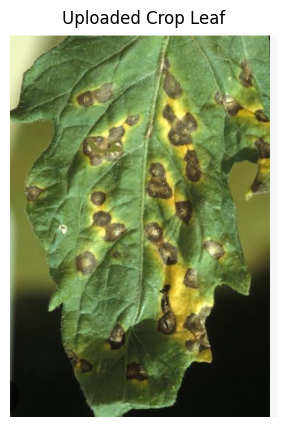

Predicted class: Tomato___Late_blight
Model confidence: 55.24%


In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Upload a crop leaf image
uploaded = files.upload()

# Get the uploaded image
image_path = next(iter(uploaded.keys()))
img = Image.open(image_path).convert("RGB")

# Resize image to the model's required input size
img_resized = img.resize((224, 224))

# Convert image to an array
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict using the saved model
with tf.device("/CPU:0"):
    predictions = loaded_model.predict(img_array, verbose=0)

# Get predicted class and confidence
predicted_index = np.argmax(predictions[0])
predicted_class = loaded_class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Display image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Uploaded Crop Leaf")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

Step 20: Add crop disease management recommendations

In [ ]:
# Crop disease management recommendation system

disease_info = {
    "Tomato___Late_blight": {
        "disease": "Tomato Late Blight",
        "symptoms": "Water-soaked spots that turn brown or dark, sometimes with pale growth on the leaf underside.",
        "management": [
            "Remove severely affected plant material where appropriate.",
            "Avoid overhead irrigation and prolonged leaf wetness.",
            "Improve spacing and airflow around plants.",
            "Use locally recommended disease-control products only as directed by agricultural experts."
        ]
    },

    "Tomato___Early_blight": {
        "disease": "Tomato Early Blight",
        "symptoms": "Brown leaf spots that may develop concentric, target-like rings.",
        "management": [
            "Remove badly affected leaves when practical.",
            "Avoid splashing soil onto leaves during watering.",
            "Mulch around plants and rotate crops where possible.",
            "Seek local agricultural guidance if the disease spreads."
        ]
    },

    "Potato___Early_blight": {
        "disease": "Potato Early Blight",
        "symptoms": "Brown leaf spots, often with concentric rings and yellowing around them.",
        "management": [
            "Remove heavily infected plant debris.",
            "Avoid unnecessary leaf wetness.",
            "Maintain suitable plant spacing.",
            "Follow local agricultural recommendations for disease control."
        ]
    },

    "Potato___Late_blight": {
        "disease": "Potato Late Blight",
        "symptoms": "Dark, rapidly spreading leaf lesions; pale growth may appear underneath in humid conditions.",
        "management": [
            "Inspect nearby plants for similar symptoms.",
            "Avoid overhead watering and prolonged leaf wetness.",
            "Remove infected material safely where appropriate.",
            "Seek prompt local agricultural advice because this disease can spread rapidly."
        ]
    }
}

info = disease_info.get(predicted_class)

print("CROP DISEASE MANAGEMENT REPORT")
print("=" * 35)
print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

if info:
    print("\nDisease:", info["disease"])
    print("\nPossible symptoms:")
    print(info["symptoms"])

    print("\nSuggested management:")
    for step, recommendation in enumerate(info["management"], start=1):
        print(f"{step}. {recommendation}")
else:
    print("\nNo specific recommendation is configured for this class yet.")
    print("Please consult a local agricultural expert for guidance.")

CROP DISEASE MANAGEMENT REPORT
Predicted class: Tomato___Late_blight
Model confidence: 55.24%

Disease: Tomato Late Blight

Possible symptoms:
Water-soaked spots that turn brown or dark, sometimes with pale growth on the leaf underside.

Suggested management:
1. Remove severely affected plant material where appropriate.
2. Avoid overhead irrigation and prolonged leaf wetness.
3. Improve spacing and airflow around plants.
4. Use locally recommended disease-control products only as directed by agricultural experts.


Step 21: Add recommendations for all 38 classes

In [ ]:

# STEP 21: Extended crop disease management recommendations
# This cell is separate from all previous code.

crop_recommendations = {
    "Apple___Apple_scab": (
        "Apple", "Apple Scab",
        "Dark olive spots on leaves or fruit.",
        ["Remove fallen infected leaves.", "Improve airflow through pruning.",
         "Seek local agricultural advice if symptoms spread."]
    ),
    "Apple___Black_rot": (
        "Apple", "Black Rot",
        "Brown leaf spots and possible fruit rot.",
        ["Remove infected fruit and plant debris.", "Prune dead branches where appropriate.",
         "Monitor nearby trees."]
    ),
    "Apple___Cedar_apple_rust": (
        "Apple", "Cedar Apple Rust",
        "Orange or yellow leaf spots.",
        ["Inspect leaves regularly.", "Remove heavily affected debris where practical.",
         "Ask a local expert about host plants and control options."]
    ),
    "Apple___healthy": (
        "Apple", "Healthy",
        "The model predicts no listed disease.",
        ["Continue regular plant monitoring.", "Maintain appropriate watering and nutrition."]
    ),
    "Blueberry___healthy": (
        "Blueberry", "Healthy",
        "The model predicts no listed disease.",
        ["Continue regular plant monitoring.", "Maintain suitable soil moisture."]
    ),
    "Cherry_(including_sour)___Powdery_mildew": (
        "Cherry", "Powdery Mildew",
        "Whitish powder-like growth on leaves.",
        ["Improve airflow around plants.", "Remove severely affected material where appropriate.",
         "Seek local advice if symptoms persist."]
    ),
    "Cherry_(including_sour)___healthy": (
        "Cherry", "Healthy",
        "The model predicts no listed disease.",
        ["Monitor leaves regularly.", "Maintain suitable growing conditions."]
    ),
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": (
        "Corn", "Cercospora / Gray Leaf Spot",
        "Rectangular gray or tan lesions on leaves.",
        ["Manage crop residue according to local guidance.", "Improve airflow where practical.",
         "Use locally recommended resistant varieties when available."]
    ),
    "Corn_(maize)___Common_rust_": (
        "Corn", "Common Rust",
        "Rust-colored raised pustules on leaves.",
        ["Monitor disease spread.", "Consider resistant varieties in future planting.",
         "Seek local agricultural advice if severe."]
    ),
    "Corn_(maize)___Northern_Leaf_Blight": (
        "Corn", "Northern Leaf Blight",
        "Long, cigar-shaped gray-green or brown leaf lesions.",
        ["Monitor nearby plants.", "Manage infected crop residue appropriately.",
         "Consider resistant varieties where available."]
    ),
    "Corn_(maize)___healthy": (
        "Corn", "Healthy",
        "The model predicts no listed disease.",
        ["Monitor crop growth.", "Maintain appropriate irrigation and nutrition."]
    ),
    "Grape___Black_rot": (
        "Grape", "Black Rot",
        "Brown leaf lesions and possible dark, shriveled berries.",
        ["Remove mummified berries and infected debris.", "Improve canopy airflow.",
         "Consult local guidance if the disease spreads."]
    ),
    "Grape___Esca_(Black_Measles)": (
        "Grape", "Esca / Black Measles",
        "Leaf discoloration and possible dark spotting on berries.",
        ["Inspect vines for recurring symptoms.", "Prune only using suitable local practices.",
         "Seek advice from a grape-growing specialist."]
    ),
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": (
        "Grape", "Leaf Blight",
        "Brown leaf spots that may spread.",
        ["Remove affected fallen leaves.", "Improve airflow through the canopy.",
         "Monitor vines regularly."]
    ),
    "Grape___healthy": (
        "Grape", "Healthy",
        "The model predicts no listed disease.",
        ["Continue vine monitoring.", "Maintain good canopy management."]
    ),
    "Orange___Haunglongbing_(Citrus_greening)": (
        "Orange", "Citrus Greening",
        "Possible blotchy leaf mottling and yellowing.",
        ["Contact a local citrus agricultural expert promptly.", "Inspect trees for other symptoms.",
         "Follow local guidance on disease-vector management."]
    ),
    "Peach___Bacterial_spot": (
        "Peach", "Bacterial Spot",
        "Small dark leaf spots that may develop holes.",
        ["Avoid unnecessary leaf wetness.", "Remove fallen affected debris where appropriate.",
         "Seek local orchard management advice."]
    ),
    "Peach___healthy": (
        "Peach", "Healthy",
        "The model predicts no listed disease.",
        ["Monitor foliage and fruit.", "Maintain suitable watering and nutrition."]
    ),
    "Pepper,_bell___Bacterial_spot": (
        "Bell Pepper", "Bacterial Spot",
        "Small dark or water-soaked spots on leaves.",
        ["Avoid handling wet plants unnecessarily.", "Remove infected debris where appropriate.",
         "Use clean tools and seek local guidance."]
    ),
    "Pepper,_bell___healthy": (
        "Bell Pepper", "Healthy",
        "The model predicts no listed disease.",
        ["Monitor plants regularly.", "Maintain suitable watering and airflow."]
    ),
    "Potato___Early_blight": (
        "Potato", "Early Blight",
        "Brown spots that may have concentric rings.",
        ["Remove severely affected foliage where appropriate.", "Avoid water splashing onto leaves.",
         "Follow local crop-protection guidance."]
    ),
    "Potato___Late_blight": (
        "Potato", "Late Blight",
        "Dark, spreading leaf lesions; pale growth may occur underneath in humid conditions.",
        ["Seek prompt local agricultural advice.", "Avoid prolonged leaf wetness.",
         "Inspect nearby plants because this disease can spread rapidly."]
    ),
    "Potato___healthy": (
        "Potato", "Healthy",
        "The model predicts no listed disease.",
        ["Continue monitoring plants.", "Maintain suitable irrigation and nutrition."]
    ),
    "Raspberry___healthy": (
        "Raspberry", "Healthy",
        "The model predicts no listed disease.",
        ["Inspect canes and leaves regularly.", "Maintain airflow and suitable soil moisture."]
    ),
    "Soybean___healthy": (
        "Soybean", "Healthy",
        "The model predicts no listed disease.",
        ["Monitor the crop regularly.", "Maintain suitable irrigation and nutrition."]
    ),
    "Squash___Powdery_mildew": (
        "Squash", "Powdery Mildew",
        "White powder-like patches on leaves.",
        ["Improve airflow around plants.", "Avoid overcrowding.",
         "Seek local advice if the infection becomes severe."]
    ),
    "Strawberry___Leaf_scorch": (
        "Strawberry", "Leaf Scorch",
        "Reddish-purple or brown leaf spots with scorched-looking areas.",
        ["Remove affected leaves where appropriate.", "Maintain suitable irrigation.",
         "Monitor plants for additional symptoms."]
    ),
    "Strawberry___healthy": (
        "Strawberry", "Healthy",
        "The model predicts no listed disease.",
        ["Continue regular monitoring.", "Maintain suitable watering and airflow."]
    ),
    "Tomato___Bacterial_spot": (
        "Tomato", "Bacterial Spot",
        "Small dark spots that may appear on leaves and fruit.",
        ["Avoid working with wet plants.", "Remove infected debris where appropriate.",
         "Seek local advice about suitable disease management."]
    ),
    "Tomato___Early_blight": (
        "Tomato", "Early Blight",
        "Brown spots that may show concentric, target-like rings.",
        ["Remove badly affected leaves where appropriate.", "Avoid splashing soil onto foliage.",
         "Improve airflow and monitor disease spread."]
    ),
    "Tomato___Late_blight": (
        "Tomato", "Late Blight",
        "Water-soaked spots that turn dark; pale growth may occur on leaf undersides in humid conditions.",
        ["Inspect nearby plants promptly.", "Avoid prolonged leaf wetness.",
         "Seek local agricultural guidance because the disease may spread rapidly."]
    ),
    "Tomato___Leaf_Mold": (
        "Tomato", "Leaf Mold",
        "Yellow patches on upper leaf surfaces and possible olive-colored growth underneath.",
        ["Improve ventilation.", "Avoid prolonged leaf wetness.",
         "Remove severely affected leaves where appropriate."]
    ),
    "Tomato___Septoria_leaf_spot": (
        "Tomato", "Septoria Leaf Spot",
        "Small circular spots with pale centers and dark edges.",
        ["Remove affected lower leaves where appropriate.", "Avoid splashing water onto foliage.",
         "Clear infected plant debris."]
    ),
    "Tomato___Spider_mites Two-spotted_spider_mite": (
        "Tomato", "Spider Mites",
        "Fine stippling, leaf bronzing, and sometimes delicate webbing.",
        ["Inspect leaf undersides.", "Monitor for mites and beneficial insects.",
         "Seek local advice on appropriate integrated pest management."]
    ),
    "Tomato___Target_Spot": (
        "Tomato", "Target Spot",
        "Brown lesions that may have concentric rings.",
        ["Improve airflow around plants.", "Avoid prolonged leaf wetness.",
         "Remove affected debris where appropriate."]
    ),
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": (
        "Tomato", "Tomato Yellow Leaf Curl Virus",
        "Yellowing, upward leaf curling, and stunted growth may occur.",
        ["Inspect plants for whiteflies.", "Seek local advice on vector management.",
         "Use locally recommended resistant varieties when available."]
    ),
    "Tomato___Tomato_mosaic_virus": (
        "Tomato", "Tomato Mosaic Virus",
        "Mottled light and dark green leaves and possible leaf distortion.",
        ["Clean hands and tools between plants.", "Remove infected plants according to local guidance.",
         "Avoid reusing contaminated plant material."]
    ),
    "Tomato___healthy": (
        "Tomato", "Healthy",
        "The model predicts no listed disease.",
        ["Continue regular monitoring.", "Maintain suitable watering and nutrition."]
    )
}

# Display report using the existing prediction variables.
print("EXTENDED CROP DISEASE MANAGEMENT REPORT")
print("=" * 45)
print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

if confidence < 60:
    print("\nCAUTION: Confidence is low. Verify the result before taking action.")

recommendation = crop_recommendations.get(predicted_class)

if recommendation:
    crop, disease, symptoms, management = recommendation
    print("\nCrop:", crop)
    print("Predicted condition:", disease)
    print("\nPossible symptoms:")
    print(symptoms)
    print("\nSuggested management:")
    for i, step in enumerate(management, start=1):
        print(f"{i}. {step}")
else:
    print("\nNo recommendation is available for this class.")
    print("Seek advice from a qualified local agricultural expert.")

print("\nNote: This is an AI-assisted prediction, not a confirmed diagnosis.")
print("Recommendations are general guidance; verify locally before acting.")
print("\nClasses covered:", len(crop_recommendations))
print("Model classes:", len(loaded_class_names))
print("Missing recommendation classes:",
      sorted(set(loaded_class_names) - set(crop_recommendations)))


EXTENDED CROP DISEASE MANAGEMENT REPORT
Predicted class: Tomato___Late_blight
Model confidence: 55.24%

CAUTION: Confidence is low. Verify the result before taking action.

Crop: Tomato
Predicted condition: Late Blight

Possible symptoms:
Water-soaked spots that turn dark; pale growth may occur on leaf undersides in humid conditions.

Suggested management:
1. Inspect nearby plants promptly.
2. Avoid prolonged leaf wetness.
3. Seek local agricultural guidance because the disease may spread rapidly.

Note: This is an AI-assisted prediction, not a confirmed diagnosis.
Recommendations are general guidance; verify locally before acting.

Classes covered: 38
Model classes: 38
Missing recommendation classes: []


Step 22A: Generate the confusion matrix and performance graphs

STEP 22: MODEL PERFORMANCE
Images evaluated: 640
Sample accuracy: 90.94%
Macro F1-score: 0.871
Weighted F1-score: 0.904


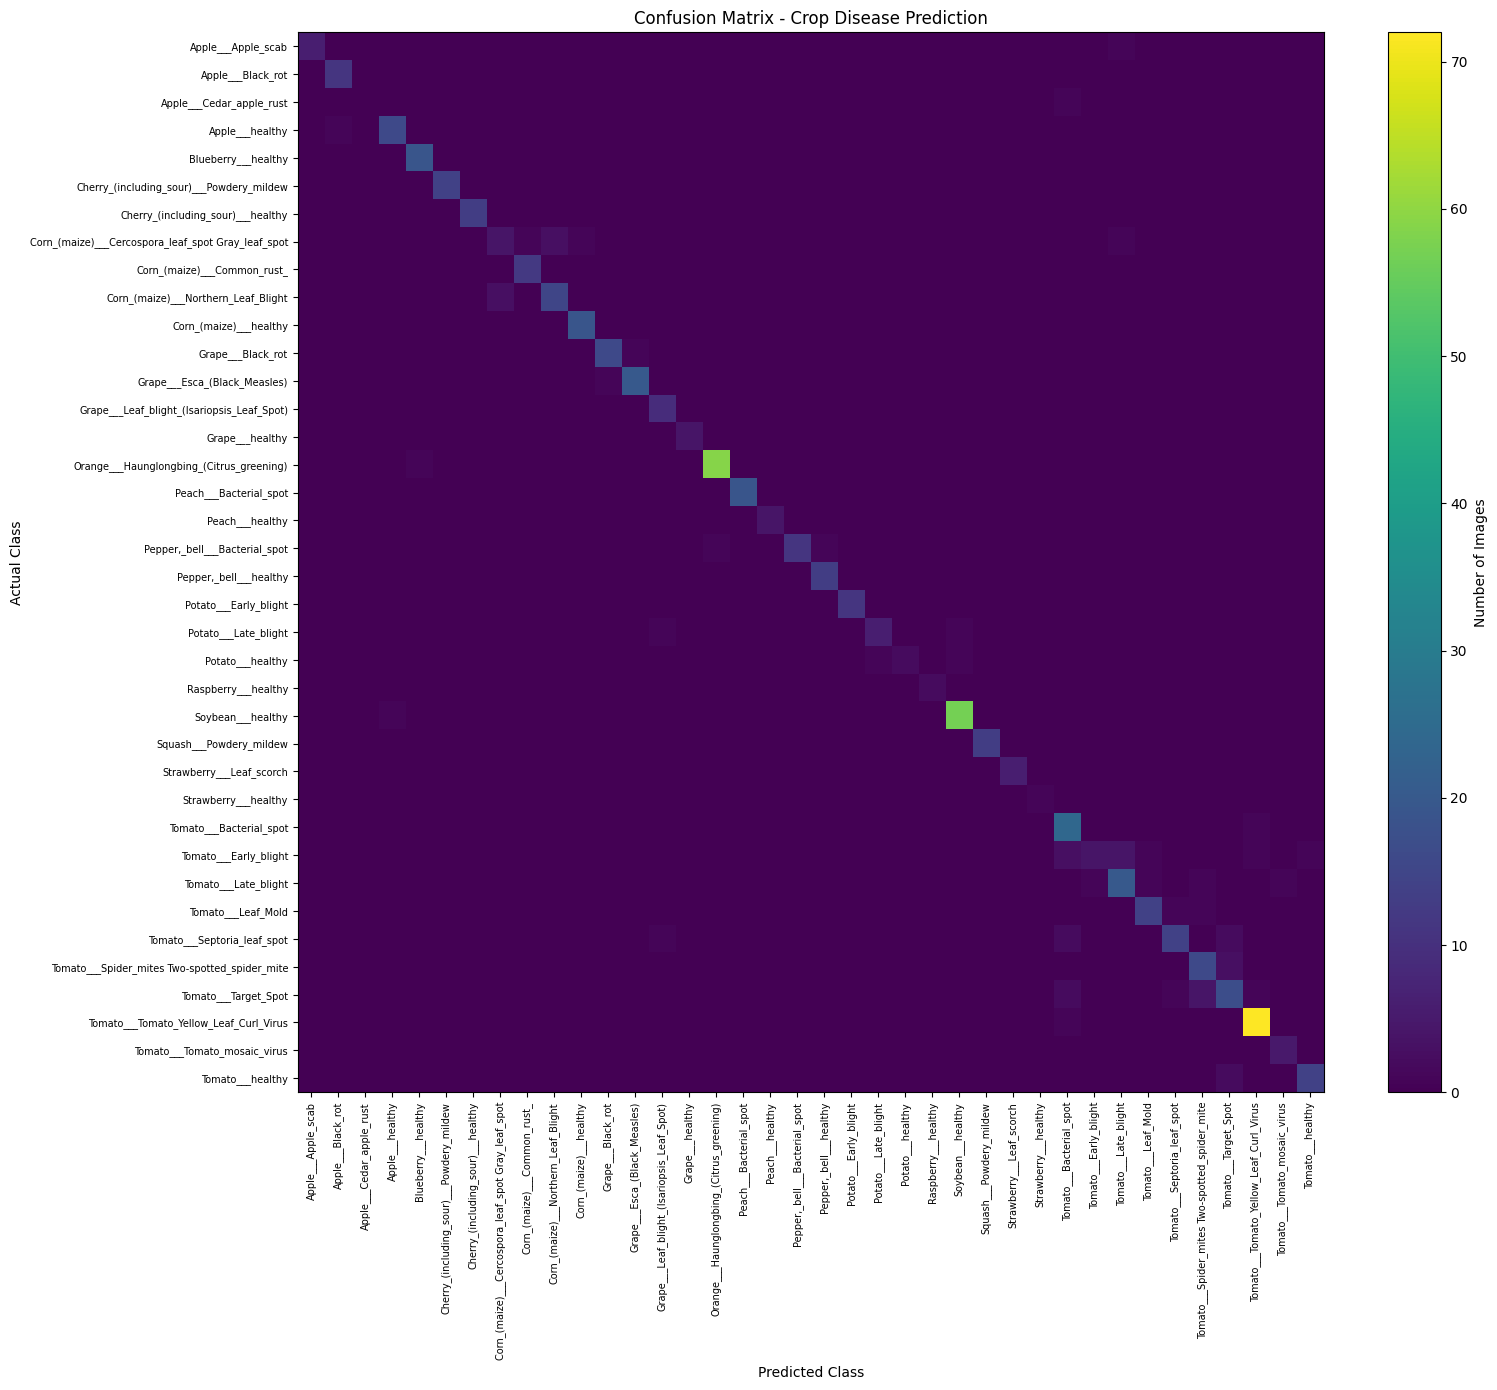

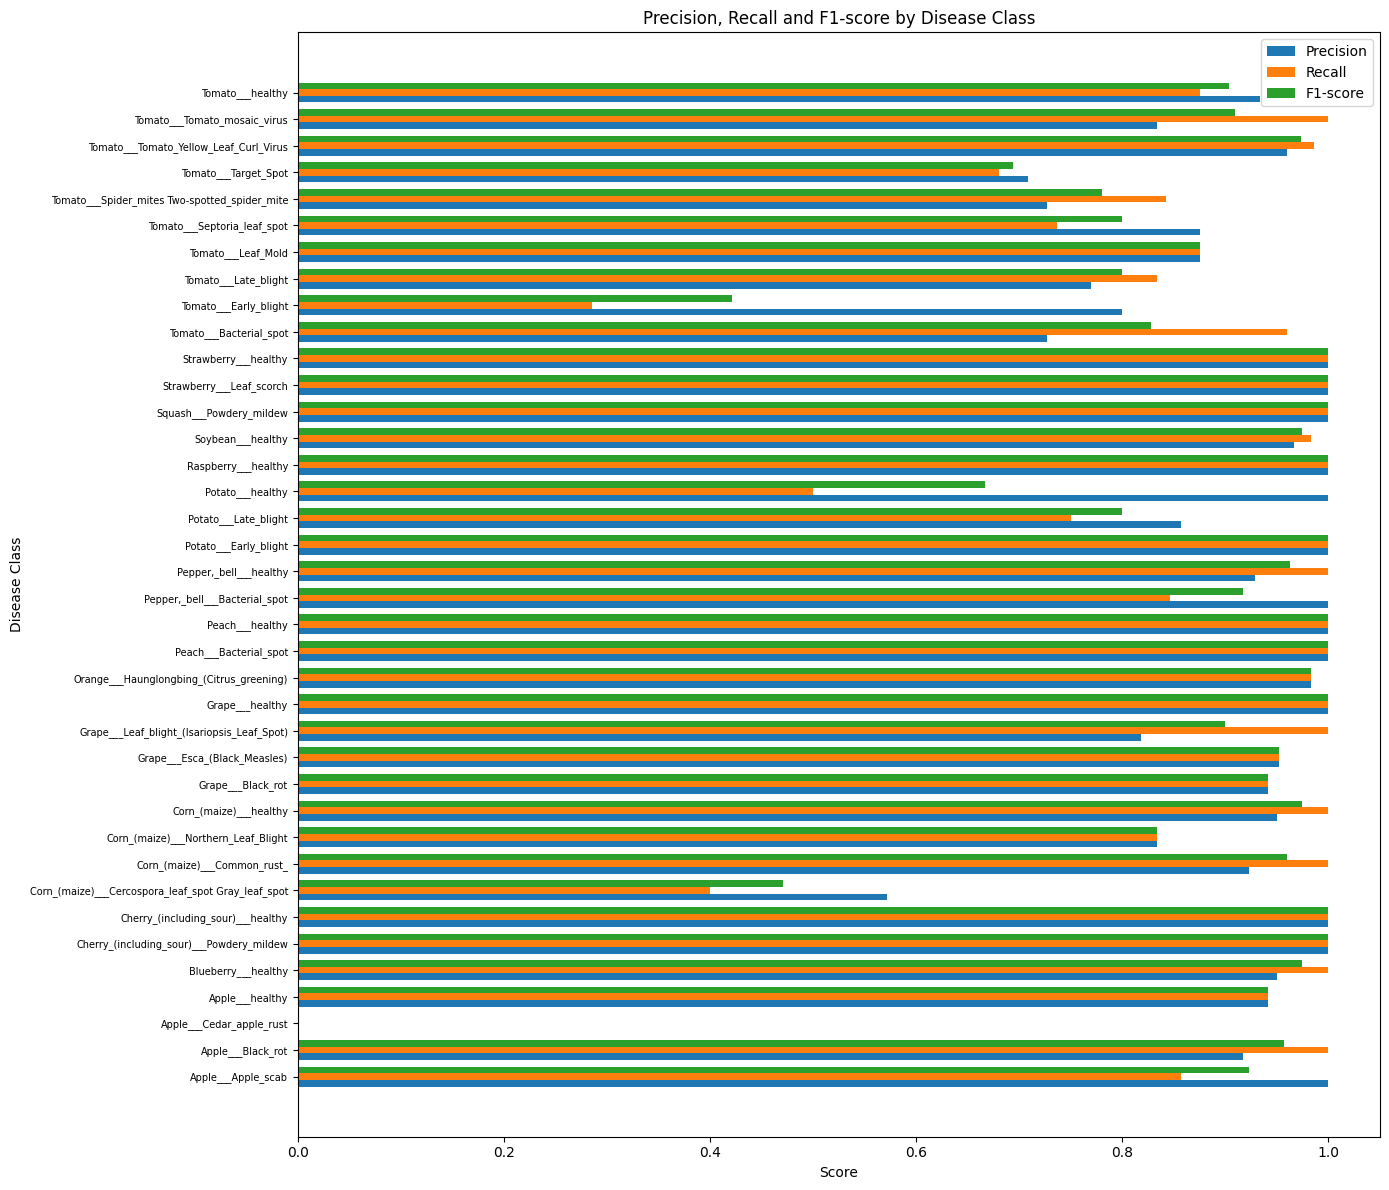


Performance graphs generated successfully.


In [ ]:

# STEP 22: Model performance evaluation and graphs
# This cell does not retrain or modify the saved model.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Check that the validation dataset is available
if "val_ds" not in globals():
    print("Validation dataset 'val_ds' is not available.")
    print("We need to recreate the validation dataset before plotting.")
else:
    y_true = []
    y_pred = []

    # Evaluate a sample of 20 batches (up to 640 images)
    for images, labels in val_ds.take(20):
        predictions = loaded_model.predict(images, verbose=0)

        y_true.extend(labels.numpy().astype(int).tolist())
        y_pred.extend(np.argmax(predictions, axis=1).tolist())

    # Calculate evaluation metrics
    class_ids = list(range(len(loaded_class_names)))

    print("STEP 22: MODEL PERFORMANCE")
    print("=" * 40)
    print("Images evaluated:", len(y_true))
    print(f"Sample accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

    report = classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=loaded_class_names,
        output_dict=True,
        zero_division=0
    )

    print(f"Macro F1-score: {report['macro avg']['f1-score']:.3f}")
    print(f"Weighted F1-score: {report['weighted avg']['f1-score']:.3f}")

    # 1. Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=class_ids)

    plt.figure(figsize=(16, 14))
    plt.imshow(cm, interpolation="nearest", aspect="auto")
    plt.title("Confusion Matrix - Crop Disease Prediction")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(class_ids, loaded_class_names, rotation=90, fontsize=7)
    plt.yticks(class_ids, loaded_class_names, fontsize=7)
    plt.colorbar(label="Number of Images")
    plt.tight_layout()
    plt.show()

    # 2. Precision, recall, and F1-score by class
    precisions = [report[name]["precision"] for name in loaded_class_names]
    recalls = [report[name]["recall"] for name in loaded_class_names]
    f1_scores = [report[name]["f1-score"] for name in loaded_class_names]

    positions = np.arange(len(loaded_class_names))
    height = 0.25

    plt.figure(figsize=(14, 12))
    plt.barh(positions - height, precisions, height, label="Precision")
    plt.barh(positions, recalls, height, label="Recall")
    plt.barh(positions + height, f1_scores, height, label="F1-score")
    plt.yticks(positions, loaded_class_names, fontsize=7)
    plt.xlabel("Score")
    plt.ylabel("Disease Class")
    plt.title("Precision, Recall and F1-score by Disease Class")
    plt.xlim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("\nPerformance graphs generated successfully.")
